In [54]:
import sys
sys.path.append("../")

from src.segmentation_pipeline import segmentation_pipeline
from src.model_run import start_prediction_machine, detectron2_instances
from src.classic_instances import instance_regions, make_instance_gif
from src.fusion import *
from src.classifier import classify_instances, load_classifiers, Category_Classifier
from src.coco_json_functions import *
from src.model_run import CLASSES
# from src.instance_based_evaluation import compare_coco
from tqdm import tqdm

from collections import defaultdict
import cv2
import numpy as np
from matplotlib import pyplot as plt


from sklearn.base import TransformerMixin, BaseEstimator
class SelectColumns(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns
    def fit(self, xs, ys, **params):
        return self
    def transform(self, xs):
        return xs[self.columns]
    
from pathlib import Path

In [55]:
multi_class = False
tangled = False

# model 2 (NMS 0.5, 50% Col-0*)
# model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2_50%.pth"

# model 2 (NMS 0.5, 100% Col-0*)
# model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2.pth"

#model 2.5 (NMS 0.5, 100% Col-0*)
# model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2.5.pth"

#model 2.5 (NMS 0.5, 50% Col-0*)
# model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2.5_50%.pth"

#model root
root_model_path = "/home/mellanie/Desktop/container/model/segmentation_models/root_model_2.5.pth"

# model 2.5 (NMS 0.5, 50% Col-0*) Trained on the 23 genotypes goven at the end of Tristan's internship
model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2.5_at_end_of_tristans_internship.pth"


####################################################################################################
# CLASSIFIERS

bmp_cls = "/home/mellanie/Desktop/container/model/classifiers/bumps_embedded_classifier.pkl"
bg_cls = "/home/mellanie/Desktop/container/model/classifiers/bg_regular_classifier.pkl"

####################################################################################################

# Detectron2 has a confidence score for each prediction. 
# Increase this If you want harsher scoring criteria
detectron_confidence_threshold = 0.0

# For fusing the model outputs and classic outputs the IoU is intnetionally set low
# to allow for more generous overlap trying to avoid there case where multipule hairs are predicted
# for only one instance.
fusion_iou_threshold = 0.1

#  Not used much since we use run length encoding
# (only used if rle not set)
epsilon = 0.0 

In [56]:
# predictor is the segmentaion model as a variable
predictor = start_prediction_machine(path_to_model=model_path, multi_class=multi_class)
root_predictor = start_prediction_machine(path_to_model=root_model_path, multi_class=multi_class)

# Make the classifier class
bmp_predictor, bg_predictor = load_classifiers(bmp_cls, bg_cls)
classifier = Category_Classifier(None, None, None, None, bmp_predictor, bg_predictor, tangled)

/home/mellanie/.local/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/mellanie/.local/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/mellanie/.local/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.6.1 when using vers

In [57]:
# go through each 5 major setps. Look at documentation pdf or hold Ctr key when left-clicking for more info
def instance_segmentation_pipeline(img_path, 
                                    max_hole_size=2000, 
                                    min_area=100, 
                                    max_distance=20, 
                                    circularity_threshold=0.8, 
                                    tangled=tangled,
                                    fusion_iou_threshold = 0.1,
                                    verbose=False, 
                                    is_stitched=False,
                                    show_overlay=True):
    
    #1. Classic Segmentation
    #   function returns the mask for the root and the mask for the hairs as seperate variables
    root, hairs = segmentation_pipeline(img_path, max_hole_size=max_hole_size, min_area=min_area, max_distance=max_distance, 
                                        circularity_threshold=circularity_threshold, verbose=verbose, 
                                        is_stitched=is_stitched, show_overlay=show_overlay) 


    #2. Separate Classic Segments by Instance
    #   get a list of each unique instance mask of root hairs
    classic_masks = instance_regions(hairs, root, tangled=tangled)
    # classic_masks = []
    
    # 3. Get the Model outputs
    #   Instances is a list of all found instances in the image, including bounding box, mask, label, and label id
    model_instances = detectron2_instances(predictor, img_path, verbose=verbose)
    model_root = detectron2_instances(root_predictor, img_path, verbose=verbose)

    #4. Fuseion
    fused_instances = fusion_of_masks(classic_masks, model_instances, iou_threshold=fusion_iou_threshold,
                                      detectron_confidence_threshold=detectron_confidence_threshold)

    #5. Classify
    classified_instances = classify_instances(fused_instances, root, img_path, classifier, tangled)
    

    return classified_instances, model_instances, classic_masks, model_root

    # return classic_masks

In [137]:
json_with_annotation_data = "/home/mellanie/Desktop/Tristan_2026_code/detectron2/training&testing_data/model2.5_data/genotypes_at_end_of_Tristan's_term/test.json"
true_root_segmentation_Data = "/home/mellanie/Desktop/Tristan_2026_code/detectron2/training&testing_data/model2.5_root_model_data/test.json"


# img_path = "/home/mellanie/Desktop/Annotated_dataset/20241002_N4_Plate1_DAG6_1000_L/000007.tif"
# img_path = "/home/mellanie/Desktop/Annotated_dataset/20241030_N4_Plate6_DAG6_1000_L/000007.tif"
# img_path = "/home/mellanie/Desktop/Annotated_dataset/20241030_N4_Plate1_DAG6_1000_L/000003.tif"
img_path = "/home/mellanie/Desktop/Annotated_dataset/20240926_N4_Plate1_DAG6_1000_L/000013.tif"

# Bay-0, N4

fused_classified_instances, model_instances, classic_masks, model_root_output = instance_segmentation_pipeline(img_path, 
                                                                                                               verbose=False, 
                                                                                                               show_overlay=False,
                                                                                                               fusion_iou_threshold=fusion_iou_threshold)

In [138]:
model_dict = load_model_instances(model_instances, detectron_confidence_threshold=detectron_confidence_threshold)
model_root_dict = load_model_instances(model_root_output, detectron_confidence_threshold=detectron_confidence_threshold)

model_masks = model_dict["masks"]
model_root = model_root_dict["masks"]

In [139]:
fused_masks = []
for item in fused_classified_instances:
    if item["category_id"] != 0:
        fused_masks.append(item["mask"])

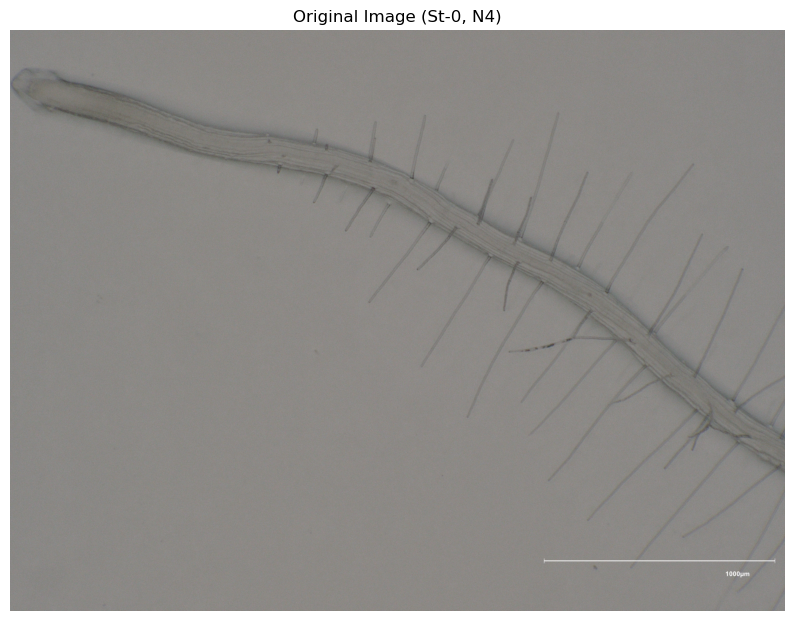

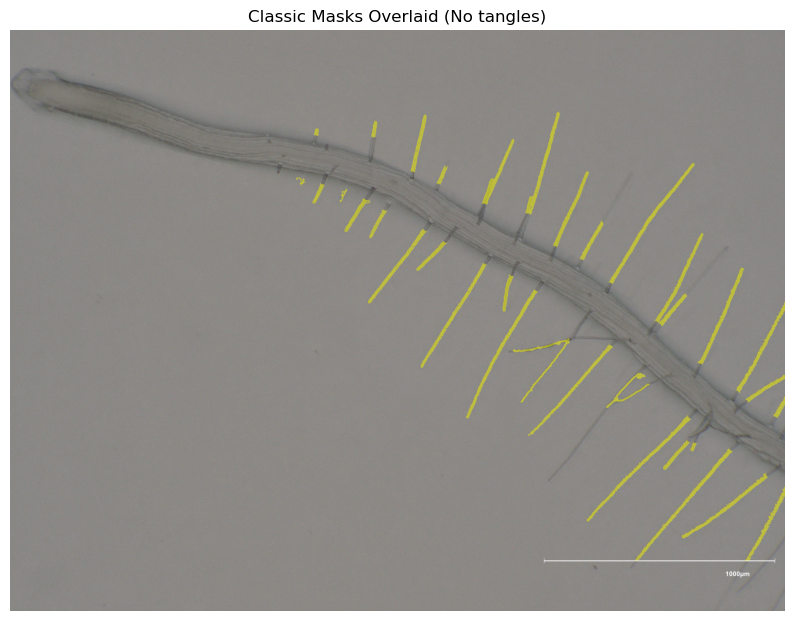

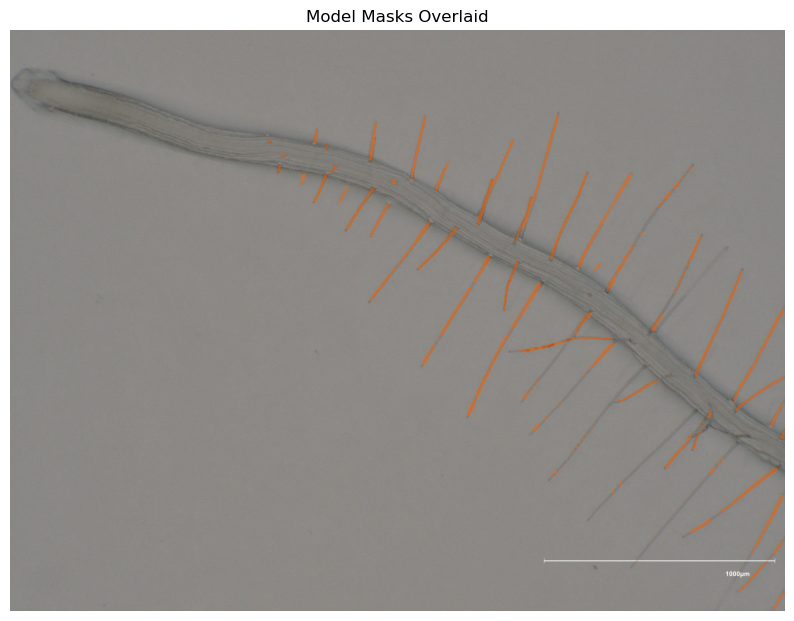

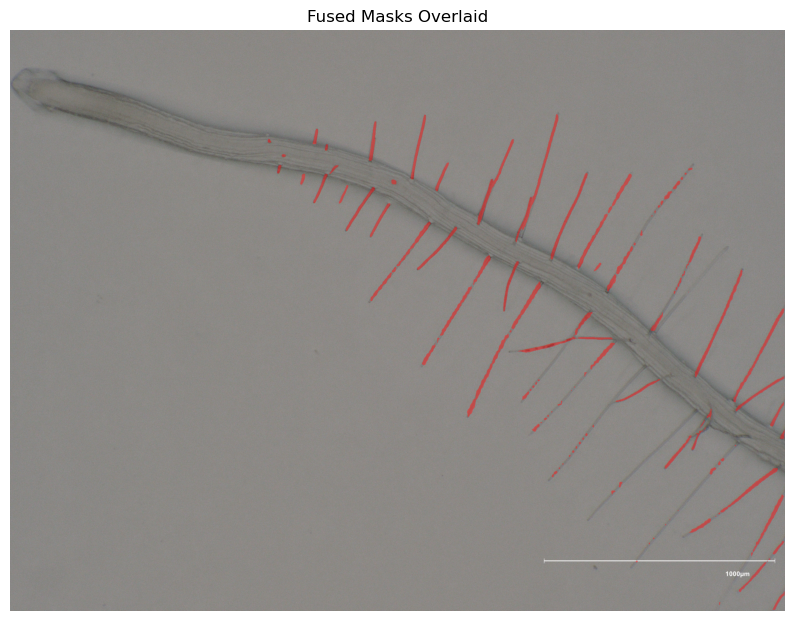

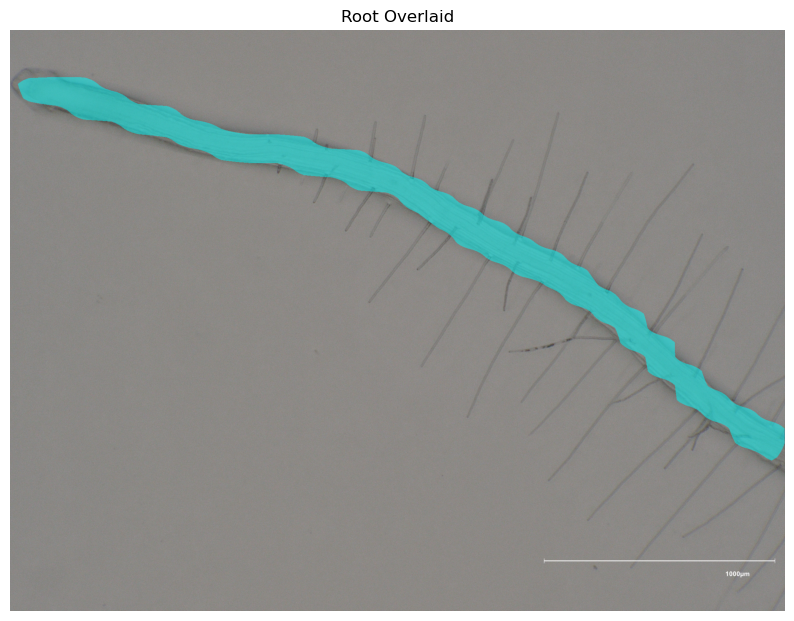

In [140]:
import cv2


COLOURS = {"yellow": [255, 255, 0],
           "orange": [255, 100, 0],
           "red": [255, 25, 25],
           "turquoise": [0, 255, 255]}

# function to iterate through a list of boolean masks and overlay them 
def overlay_image(img_path, masklist, title, colour=[255, 165, 0]):
    image = cv2.imread(img_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    overlay = image_rgb.copy()
    orange = np.array(colour, dtype=np.uint8)

    for mask in masklist:
        overlay[mask.astype(bool)] = orange

    alpha = 0.5  # blend strength
    blended = cv2.addWeighted(overlay, alpha, image_rgb, 1 - alpha, 0)

    plt.figure(figsize=(10, 8))
    plt.imshow(blended)
    plt.axis("off")
    plt.title(title)
    plt.savefig(f"plots_for_poster/{title}.png", dpi=300, bbox_inches='tight')  # save FIRST
    plt.show()

overlay_image(img_path, [], "Original Image (St-0, N4)", colour=COLOURS["yellow"])
overlay_image(img_path, classic_masks, "Classic Masks Overlaid (No tangles)", colour=COLOURS["yellow"])
overlay_image(img_path, model_masks, "Model Masks Overlaid", colour=COLOURS["orange"])
overlay_image(img_path, model_masks, "Fused Masks Overlaid", colour=COLOURS["red"])
overlay_image(img_path, model_root, "Root Overlaid", colour=COLOURS["turquoise"])

In [141]:
with open(json_with_annotation_data, "r") as f:
    data = json.load(f)

with open(true_root_segmentation_Data, "r") as l:
    root_data = json.load(l)


id = 0
height = 0
width = 0
for image_data in data["images"]:
    if image_data["file_name"] == img_path:
        id = image_data["id"]
        print("id", id)
        height = image_data["height"]
        width = image_data["width"]
        break


root_id = 0
root_height = 0
root_width = 0
for image_data in root_data["images"]:
    if image_data["file_name"] == img_path:
        root_id = image_data["id"]
        print("root id", id)
        root_height = image_data["height"]
        root_width = image_data["width"]
        break


    

id 21
root id 21


In [142]:
def polygon_to_mask(segmentation, height, width):
    """Decode a COCO polygon or RLE segmentation to a boolean mask."""
    if isinstance(segmentation, dict):
        # RLE format: {"size": [H, W], "counts": "..."}
        if isinstance(segmentation["counts"], str):
            segmentation["counts"] = segmentation["counts"].encode("utf-8")
        return maskUtils.decode(segmentation).astype(bool)
    else:
        # Polygon format: [[x1, y1, x2, y2, ...]]
        rles = maskUtils.frPyObjects(segmentation, height, width)
        rle  = maskUtils.merge(rles)
        return maskUtils.decode(rle).astype(bool)

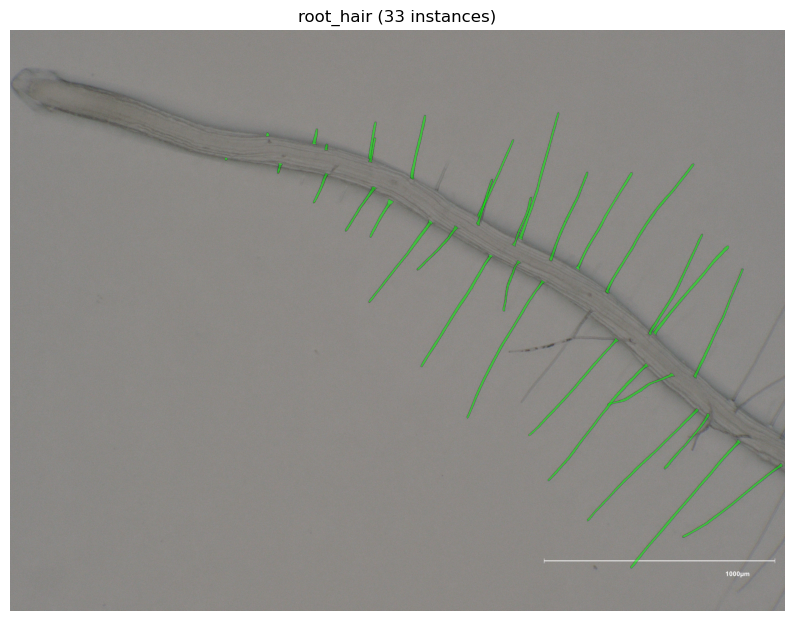

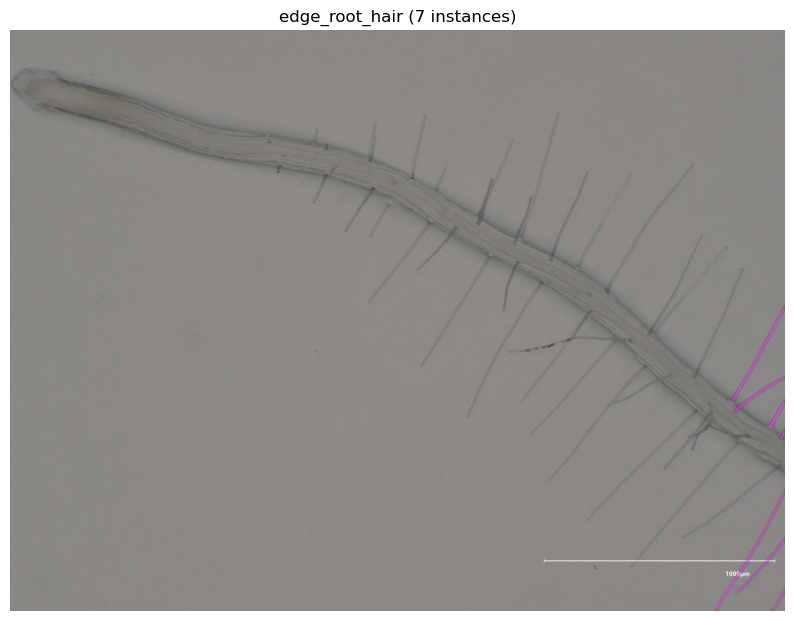

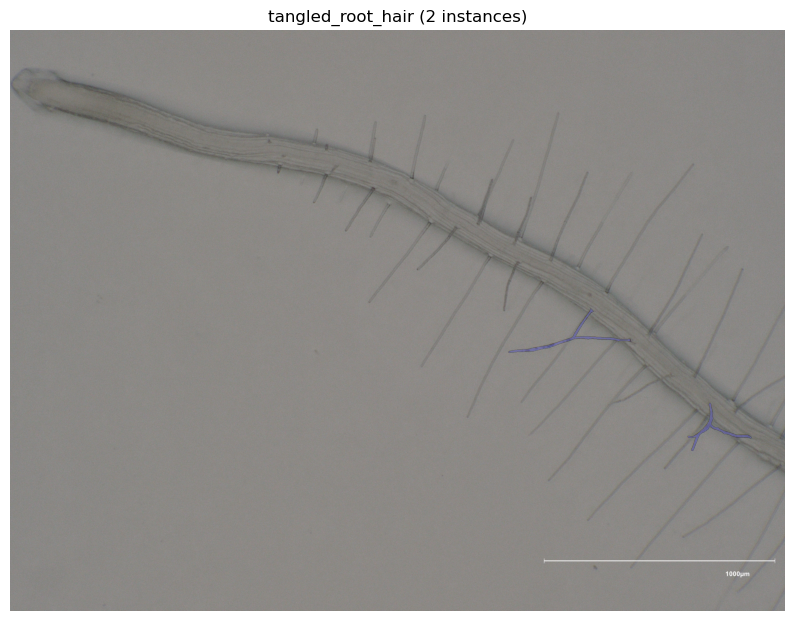

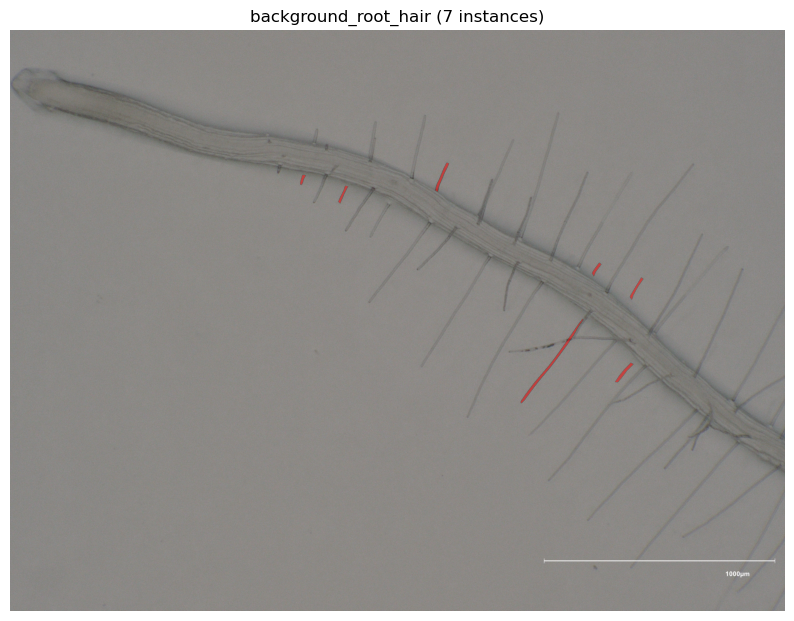

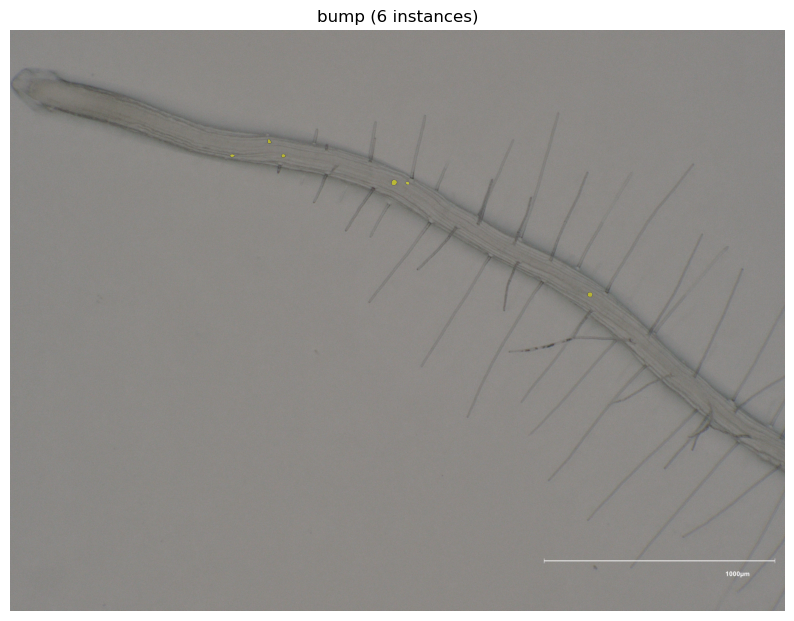

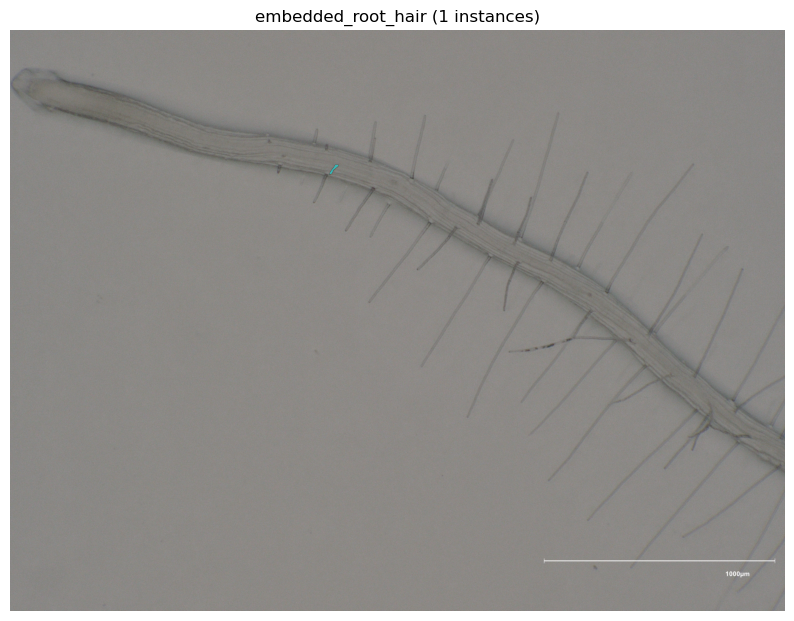

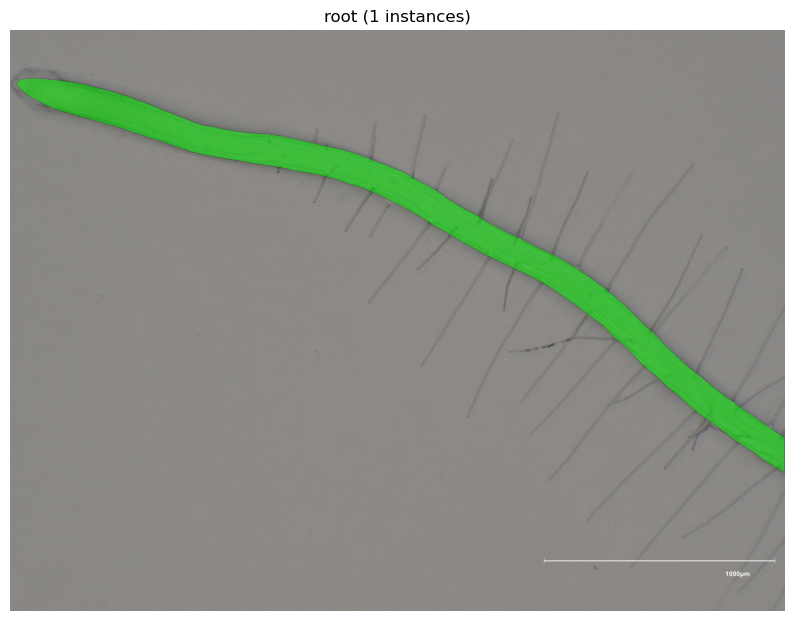

In [143]:
# for annotation_data in data["annotations"]:

segments = [annotation_data for annotation_data in data["annotations"] if annotation_data["image_id"] == id]
root_segments = [annotation_data for annotation_data in root_data["annotations"] if annotation_data["image_id"] == root_id]
segments.append(root_segments[0])


from collections import defaultdict
import cv2
import numpy as np
from matplotlib import pyplot as plt

image = cv2.imread(img_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Group masks by category
masks_by_category = defaultdict(list)
for instance in segments:
    masks_by_category[instance["old_category"]].append(instance["segmentation"])


COLOURS = [(0, 255, 0, 128),
           (255, 50, 255, 128),
           (100, 100, 200, 128),
           (255, 0, 0, 128),
           (255, 255, 0, 128),
           (0, 255, 255, 128)]

# Plot one figure per category, with all its masks overlaid
index = 0
for cat_name, mask_list in masks_by_category.items():

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(image)
    
    for segments in mask_list:
        mask = polygon_to_mask(segments, height, width)
        overlay = np.zeros((*mask.shape, 4), dtype=np.uint8)

        colour_index = index%len(COLOURS)
        overlay[mask] = COLOURS[colour_index]

        ax.imshow(overlay)

    index += 1
    
    ax.axis("off")
    ax.set_title(f"{cat_name} ({len(mask_list)} instances)")

    # ax.figure.savefig(f"plots_for_poster/instances/{cat_name}.png", dpi=300, bbox_inches='tight')  
    plt.show()

  



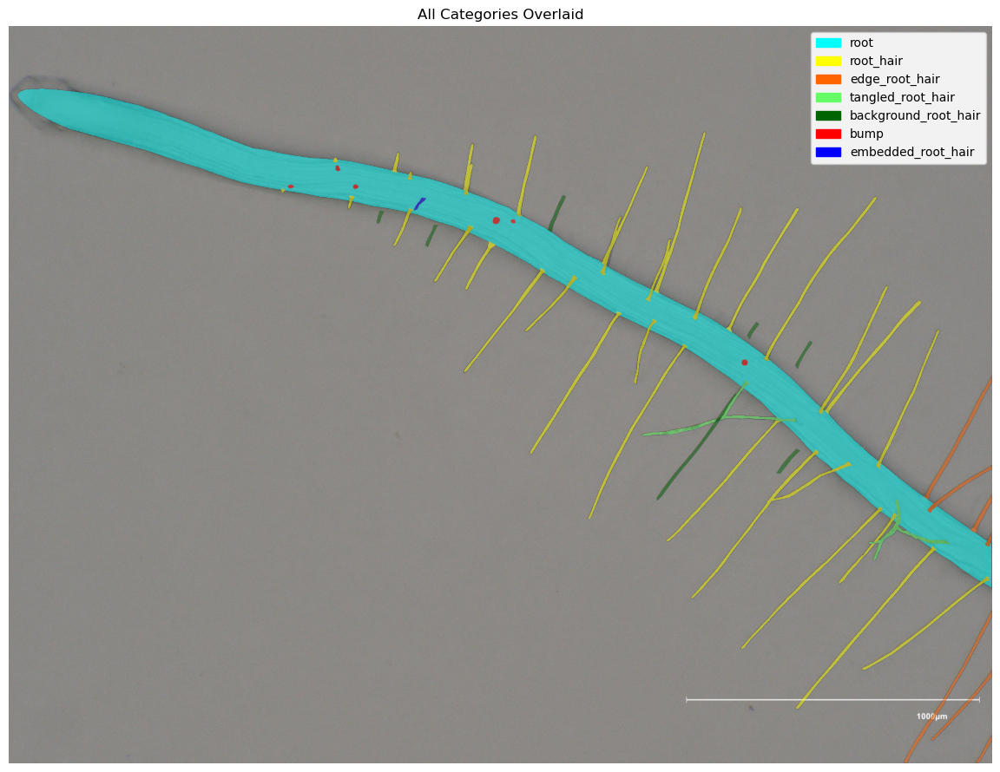

In [152]:
segments = [annotation_data for annotation_data in data["annotations"] if annotation_data["image_id"] == id]
root_segments = [annotation_data for annotation_data in root_data["annotations"] if annotation_data["image_id"] == root_id]
segments.insert(0, root_segments[0])

from collections import defaultdict
import cv2
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as mpatches

image = cv2.imread(img_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Group masks by category
masks_by_category = defaultdict(list)
for instance in segments:
    masks_by_category[instance["old_category"]].append(instance["segmentation"])

COLOURS = {"root": (0, 255, 255, 128),
           "root_hair": (255, 255, 0, 128),
           "bump": (255, 0, 0, 128),
           "embedded_root_hair": (0, 0, 255, 128),
           "edge_root_hair": (255, 100, 0, 128),
           "tangled_root_hair": (100, 255, 100, 128),
           "background_root_hair": (0, 100, 0, 128)}

# One shared overlay for the whole image
overlay = np.zeros((*image.shape[:2], 4), dtype=np.uint8)

# Assign one consistent colour per category
category_names = list(masks_by_category.keys())
# category_colours = {cat: COLOURS[i % len(COLOURS)] for i, cat in enumerate(category_names)}

# Paint every category's masks into the same overlay
for cat_name, mask_list in masks_by_category.items():
    colour = COLOURS[cat_name]
    for segmentation in mask_list:
        mask = polygon_to_mask(segmentation, height, width)
        overlay[mask] = colour

# --- Plot everything on ONE figure ---
fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(image)
ax.imshow(overlay)
ax.axis("off")
ax.set_title("All Categories Overlaid")

# Legend: one patch per category, using its true colour
legend_handles = [
    mpatches.Patch(color=np.array(COLOURS[cat][:3]) / 255, label=cat)
    for cat in category_names
]
ax.legend(handles=legend_handles, loc="upper right", fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.savefig("plots_for_poster/all_categories_overlay.png", dpi=300, bbox_inches='tight')
plt.show()

In [145]:
from collections import defaultdict

categories_by_image = defaultdict(set)

for ann in data["annotations"]:
    categories_by_image[ann["image_id"]].add(ann["old_category"])

# categories_by_image

# Find image(s) with exactly 6 unique category ids
target_images = [img_id for img_id, cats in categories_by_image.items() if len(cats) >= 6]

print(target_images)

[12, 15, 18, 20, 21, 22, 23, 27, 29, 30, 31, 33, 34, 35, 37, 38, 39, 41, 43, 44, 46, 54, 55, 56, 58, 59]


In [146]:
data

{'images': [{'id': 0,
   'file_name': '/home/mellanie/Desktop/Annotated_dataset/20240918_N4_Plate1_DAG6_1000_L/000001.tif',
   'width': 2048,
   'height': 1536,
   'ecotype': 'Pu2-23'},
  {'id': 1,
   'file_name': '/home/mellanie/Desktop/Annotated_dataset/20240918_N4_Plate1_DAG6_1000_L/000002.tif',
   'width': 2048,
   'height': 1536,
   'ecotype': 'Pu2-23'},
  {'id': 2,
   'file_name': '/home/mellanie/Desktop/Annotated_dataset/20240918_N4_Plate1_DAG6_1000_L/000003.tif',
   'width': 2048,
   'height': 1536,
   'ecotype': 'Pu2-23'},
  {'id': 3,
   'file_name': '/home/mellanie/Desktop/Annotated_dataset/20240918_N4_Plate1_DAG6_1000_L/000008.tif',
   'width': 2048,
   'height': 1536,
   'ecotype': 'Ws-0'},
  {'id': 4,
   'file_name': '/home/mellanie/Desktop/Annotated_dataset/20240918_N4_Plate1_DAG6_1000_L/000009.tif',
   'width': 2048,
   'height': 1536,
   'ecotype': 'Ws-0'},
  {'id': 5,
   'file_name': '/home/mellanie/Desktop/Annotated_dataset/20240918_N4_Plate1_DAG6_1000_L/000010.tif',
